In [ ]:
import pandas as pd
import numpy as np
from sklearn import datasets
import matplotlib.pylab as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, HuberRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.neural_network import MLPRegressor

In [ ]:
# ----------------------------
# Load and Prepare the Data
# ----------------------------
# Read CSV data
from pathlib import Path

_candidates = [
    Path("data/processed/ECOLI_W_API.csv"),
    Path("../../data/processed/ECOLI_W_API.csv"),
]
_path = next((p for p in _candidates if p.exists()), None)
if _path is None:
    raise FileNotFoundError(
        "Could not find data/processed/ECOLI_W_API.csv. "
        "Run this notebook from the repo root or from src/modeling."
    )
df = pd.read_csv(_path)

# Normalize column names by removing spaces
df.columns = df.columns.str.replace(' ', '')

# Filter out rows with high RESULT values
# df = df[df['RESULT..MPN.100ML.'] < 2000]

# Define feature set
features = [
    'TEMPERATURE', 'HUMIDITY', 'PRECIPITATION', 'DEW', 'WINDSPEED', 'WINDGUST',
    'WINDDIR', 'PRESSURE', 'CLOUDCOVER', 'SOLARRADIATION', 'SOLARENERGY', 'UVINDEX'
]

# Fill missing values in the features columns with their mean value
df[features] = df[features].fillna(df[features].mean())

# Define input X and target y
X = df[features]
y = df['RESULT..MPN.100ML.']
y_log = np.log(y + 1)

# ----------------------------
# Split Data into Training and Testing Sets
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y_log, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# ----------------------------
# Build, Fit, and Evaluate Models
# ----------------------------

# Function to fit model, get metrics, and return results
def evaluate_model(model, model_name):
    # Fit the model
    model.fit(X_train, y_train)

    # Make predictions on test set
    y_pred = model.predict(X_test)

    # Compute metrics
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Output model coefficients (if available) and intercept
    if hasattr(model, 'coef_'):
        coefficients = model.coef_
    else:
        coefficients = None
    intercept = model.intercept_

    # Print results
    print(f"---------- {model_name} ----------")
    print("Coefficients:")
    print(coefficients)
    print("Intercept:", intercept)
    print("Mean Squared Error:", mse)
    print("R² Score:", r2)
    print("\n")

    return y_test, y_pred, coefficients, intercept, mse, r2

# Build Linear Regression Model
lin_reg_model = LinearRegression()
results_lin = evaluate_model(lin_reg_model, "Linear Regression")

# Build Huber Regression Model
# You can adjust the epsilon parameter if needed.
huber_model = HuberRegressor(epsilon=1.35)
results_huber = evaluate_model(huber_model, "Huber Regression")

# ----------------------------
# Plotting the Results
# ----------------------------
# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot for Linear Regression
axes[0].scatter(results_lin[0], results_lin[1], alpha=0.6)
axes[0].plot([results_lin[0].min(), results_lin[0].max()],
             [results_lin[0].min(), results_lin[0].max()],
             'r--', lw=2)
axes[0].set_title('Linear Regression: True vs Predicted')
axes[0].set_xlabel('True Values')
axes[0].set_ylabel('Predicted Values')

# Plot for Huber Regression
axes[1].scatter(results_huber[0], results_huber[1], alpha=0.6)
axes[1].plot([results_huber[0].min(), results_huber[0].max()],
             [results_huber[0].min(), results_huber[0].max()],
             'r--', lw=2)
axes[1].set_title('Huber Regression: True vs Predicted')
axes[1].set_xlabel('True Values')
axes[1].set_ylabel('Predicted Values')

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'ECOLI_W_API.csv'

In [ ]:
#Neural Net
nn_model = MLPRegressor(
    hidden_layer_sizes=(1024,1024,512,512,256,256,128,128,64,64,64,32,32,32),             # Reduce the number of neurons and layers for speed
    activation='relu',                                                          # ReLU activation function for faster training
    max_iter=500,                                                               # Limit iterations (epochs) to 300
    solver='adam',                                                              # Adam solver for faster convergence
    early_stopping=True,                                                        # Enable early stopping
    n_iter_no_change=10,                                                        # Stop after 10 iterations with no improvement
    batch_size=64,                                                              # Mini-batch size
    random_state=42                                                             # For reproducibility
)

# Train the neural network model
nn_model.fit(X_train, y_train)

# Make predictions
y_pred_nn = nn_model.predict(X_test)

# Calculate performance metrics
mse_nn = mean_squared_error(y_test, y_pred_nn)
r2_nn = r2_score(y_test, y_pred_nn)

# Output results
# print("Neural Network Results:")
# print("Weights (Coefficients):")
# print(nn_model.coefs_)  # Coefficients (weights) for each layer

# print("Biases:")
# print(nn_model.intercepts_)  # Biases for each layer

print("Mean Squared Error:", mse_nn)
print("R² Score:", r2_nn)

import numpy as np
import pandas as pd

# Get the absolute sum of weights from input to first hidden layer
input_weights = np.abs(nn_model.coefs_[0])  # shape: (n_features, n_neurons_in_first_layer)

# Sum weights across the neurons for each input feature
feature_importance = np.sum(input_weights, axis=1)

# If you have feature names, plug them here; otherwise use generic ones
feature_names = X_train.columns

# Create a DataFrame for better visualization and sorting
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

# Sort features by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Display
print("Top features based on input layer weight magnitudes:")
print(importance_df)

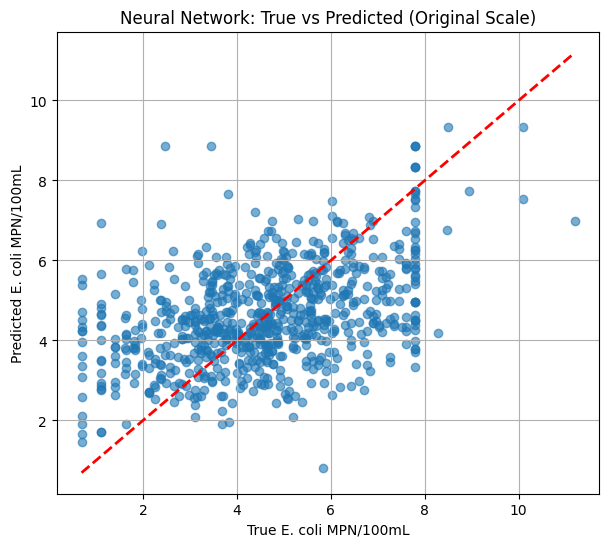

In [ ]:
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred_nn, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--', lw=2)
plt.title('Neural Network: True vs Predicted (Original Scale)')
plt.xlabel('True E. coli MPN/100mL')
plt.ylabel('Predicted E. coli MPN/100mL')
plt.grid(True)
plt.show()

import matplotlib.pyplot as plt

# Normalize importance scores to percentage
importance_df['Importance (%)'] = 100 * importance_df['Importance'] / importance_df['Importance'].sum()
importance_df['Importance (%)'] = importance_df['Importance (%)'].round(2)

# Plotting the importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance (%)'], color='skyblue')
plt.xlabel('Importance (%)')
plt.title('Feature Importance Based on Input Layer Weights (Normalized)')
plt.gca().invert_yaxis()  # So the most important feature is at the top
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()